Packages

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import rbf_kernel
from scipy.linalg import fractional_matrix_power, eigh
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import matplotlib.pyplot as plt

Input Data

In [ ]:
df = pd.read_excel('data.xlsx')
df

,Provinsi,Mabuk,Judi,Meninggalkan salah satu pihak,KDRT,Perselisihan dan pertengkaran,Murtad,Ekonomi
0,Aceh,0.001341,0.004190,0.112135,0.017097,0.823835,0.002011,0.039390
1,Sumatera Utara,0.000770,0.007766,0.068352,0.008729,0.879854,0.004685,0.029844
2,Sumatera Barat,0.000125,0.000376,0.107617,0.002380,0.873089,0.002255,0.014157
3,Riau,0.000943,0.002710,0.093919,0.008367,0.864129,0.002710,0.027221
4,Jambi,0.001775,0.004881,0.071888,0.010872,0.872199,0.003550,0.034835
5,Sumatera Selatan,0.002836,0.004694,0.093389,0.025328,0.812732,0.004889,0.056131
6,Bengkulu,0.002492,0.004431,0.075325,0.011908,0.869288,0.002492,0.034063
7,Lampung,0.005154,0.005798,0.047742,0.011953,0.722854,0.003364,0.203135
8,Kepulauan Bangka Belitung,0.009511,0.014493,0.081522,0.028080,0.658062,0.003623,0.204710
9,Kepulauan Riau,0.000923,0.001231,0.118190,0.004001,0.818098,0.005232,0.052324


In [ ]:
df_numerik = df.drop(columns=['Provinsi'])

Eksplorasi Data

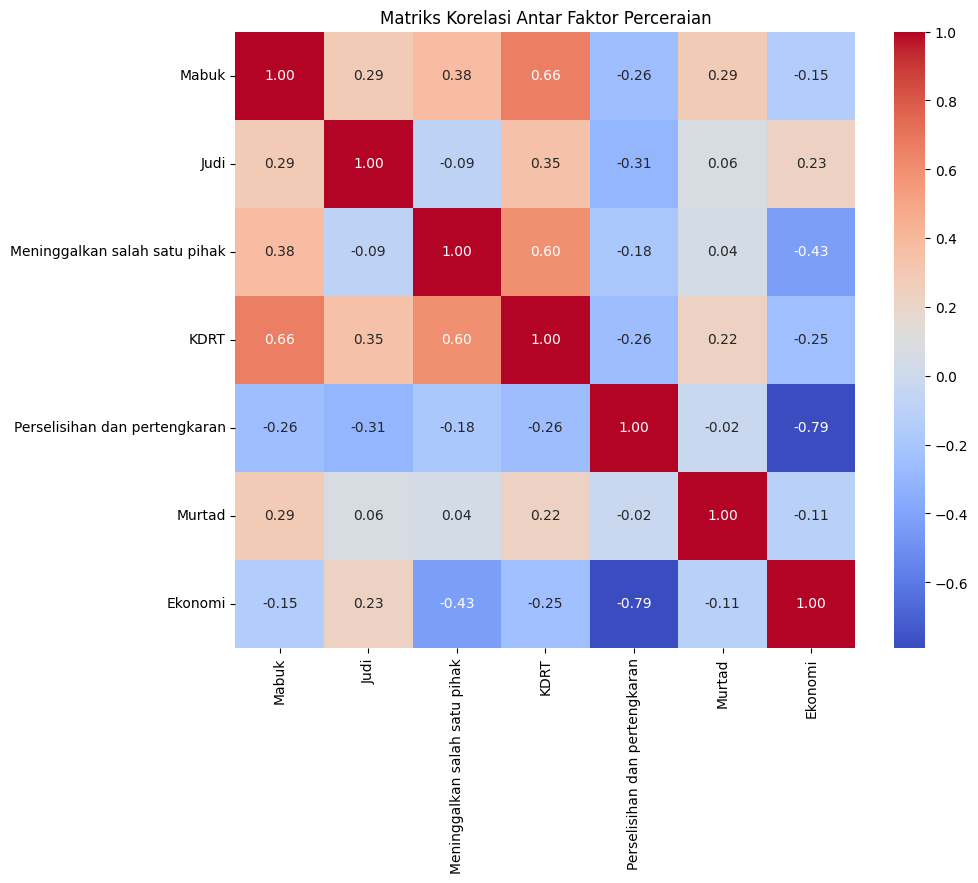

In [ ]:
# Mengecek korelasi antar faktor perceraian (tanpa kolom Provinsi)
korelasi = df.drop(columns=['Provinsi']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Antar Faktor Perceraian')
plt.show()

Affinity Matrix

In [ ]:
# Affinity matrix (Gaussian kernel)
affinity_matrix = rbf_kernel(df_numerik, gamma=0.5)

# Tampilkan affinity matrix
print(affinity_matrix)

[[1.         0.9973852  0.99834348 ... 0.9907933  0.96295952 0.99819458]
 [0.9973852  1.         0.99903307 ... 0.97939179 0.94461023 0.99176067]
 [0.99834348 0.99903307 1.         ... 0.98523261 0.94678658 0.99419909]
 ...
 [0.9907933  0.97939179 0.98523261 ... 1.         0.97576961 0.99640402]
 [0.96295952 0.94461023 0.94678658 ... 0.97576961 1.         0.97376067]
 [0.99819458 0.99176067 0.99419909 ... 0.99640402 0.97376067 1.        ]]


Degree Matrix

In [ ]:
# Degree matrix
degree_matrix = np.diag(affinity_matrix.sum(axis=1))

Laplacian simetris matrix

In [ ]:
# Laplacian simetris
laplacian = degree_matrix - affinity_matrix
d_inv_sqrt = fractional_matrix_power(degree_matrix, -0.5)
laplacian_sym = d_inv_sqrt @ laplacian @ d_inv_sqrt

In [ ]:
laplacian_sym

array([[ 0.97006565, -0.0299715 , -0.02998438, ..., -0.02970642,
        -0.02901183, -0.02985429],
       [-0.0299715 ,  0.96983375, -0.03012108, ..., -0.0294781 ,
        -0.02856903, -0.02977653],
       [-0.02998438, -0.03012108,  0.96986576, ..., -0.02963816,
        -0.02861965, -0.0298339 ],
       ...,
       [-0.02970642, -0.0294781 , -0.02963816, ...,  0.96996935,
        -0.02944502, -0.02984863],
       [-0.02901183, -0.02856903, -0.02861965, ..., -0.02944502,
         0.96967755, -0.0293117 ],
       [-0.02985429, -0.02977653, -0.0298339 , ..., -0.02984863,
        -0.0293117 ,  0.97011776]])

Eigen decomposition

In [ ]:
# Eigen decomposition
eigvals, eigvecs = eigh(laplacian_sym)
max_clusters = 3  # Jumlah maksimum cluster yang diuji
X = eigvecs[:, :max_clusters]

In [ ]:
X

array([[-1.72272621e-01, -1.04273521e-01, -6.52385939e-02],
       [-1.71609197e-01, -1.51534232e-01, -2.01593555e-01],
       [-1.71700320e-01, -1.62314722e-01, -1.16216158e-01],
       [-1.71850924e-01, -1.43776433e-01, -1.37532508e-01],
       [-1.71734864e-01, -1.41915379e-01, -1.89969933e-01],
       [-1.72367297e-01, -8.02370938e-02, -9.51393152e-02],
       [-1.71776900e-01, -1.40612676e-01, -1.79593234e-01],
       [-1.71823062e-01,  1.21294767e-01, -1.99465579e-01],
       [-1.71660850e-01,  1.71859241e-01, -6.14086998e-02],
       [-1.72348971e-01, -8.94502200e-02, -6.32398886e-02],
       [-1.72037263e-01,  1.33700931e-01,  5.20209173e-02],
       [-1.66193680e-01,  4.50477815e-01, -2.00574976e-01],
       [-1.68164466e-01,  3.83125890e-01, -1.85422606e-02],
       [-1.72588626e-01,  8.88166104e-03, -6.36929785e-02],
       [-1.64373469e-01,  5.21582423e-01, -6.38629852e-02],
       [-1.71297404e-01,  1.79208830e-01, -1.97046242e-01],
       [-1.72048309e-01, -1.20311236e-01

Normalisasi decomposition

In [ ]:
# Normalisasi baris
Y = normalize(X, norm='l2')

In [ ]:
Y

array([[-0.81384898, -0.49260816, -0.30819966],
       [-0.56257056, -0.49676066, -0.66086551],
       [-0.6520791 , -0.61643472, -0.44136276],
       [-0.65365906, -0.5468738 , -0.52312416],
       [-0.58656184, -0.48471315, -0.64884387],
       [-0.81074788, -0.37740369, -0.44749787],
       [-0.60158661, -0.49244516, -0.6289605 ],
       [-0.59276791,  0.41845166, -0.68813111],
       [-0.6851428 ,  0.68593463, -0.24509799],
       [-0.84394804, -0.43801444, -0.30966927],
       [-0.76800104,  0.5968617 ,  0.23222945],
       [-0.31937835,  0.86569394, -0.3854497 ],
       [-0.40152154,  0.91477886, -0.04427283],
       [-0.93706164,  0.04822255, -0.34581796],
       [-0.29854257,  0.94732173, -0.11599086],
       [-0.54091746,  0.56589991, -0.62222632],
       [-0.70012954, -0.48959185, -0.5197292 ],
       [-0.71555069, -0.23310032,  0.65852217],
       [-0.43983806, -0.06473792,  0.89574074],
       [-0.96686623, -0.23115438,  0.108339  ],
       [-0.86929912, -0.18142978,  0.459

Jumlah kluster optimal

In [ ]:
# Cari jumlah cluster optimal
sil_scores = []
range_n_clusters = range(2, 5)
for n_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(Y)
    score = silhouette_score(Y, labels)
    sil_scores.append(score)

optimal_k = range_n_clusters[np.argmax(sil_scores)]
print("Optimal number of clusters (k):", optimal_k)

Optimal number of clusters (k): 3


K-Means Klustering

In [ ]:
# Final KMeans clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto') # n_init
final_labels = kmeans.fit_predict(Y)

# Menambahkan kolom 'Labels' ke df_baru
df['Labels'] = final_labels

# Tampilkan df_baru untuk memeriksa hasilnya
print(df)

                     Provinsi  Mabuk  Judi  Meninggalkan salah satu pihak  \
0                        Aceh   0.00  0.00                           0.11   
1              Sumatera Utara   0.00  0.01                           0.07   
2              Sumatera Barat   0.00  0.00                           0.11   
3                        Riau   0.00  0.00                           0.09   
4                       Jambi   0.00  0.00                           0.07   
5            Sumatera Selatan   0.00  0.00                           0.09   
6                    Bengkulu   0.00  0.00                           0.08   
7                     Lampung   0.01  0.01                           0.05   
8   Kepulauan Bangka Belitung   0.01  0.01                           0.08   
9              Kepulauan Riau   0.00  0.00                           0.12   
10                DKI Jakarta   0.00  0.00                           0.14   
11                 Jawa Barat   0.00  0.00                           0.04   

Hasil Klustering

In [ ]:
# Buat DataFrame hasil cluster
tabel_cluster = df[['Provinsi', 'Labels']].copy()

# Gabungkan nama-nama provinsi per cluster jadi satu baris
tabel_ringkas = tabel_cluster.groupby('Labels')['Provinsi'].apply(lambda x: ', '.join(x)).reset_index()

# Ubah nama kolom
tabel_ringkas.columns = ['Cluster', 'Daftar Provinsi']

# Tampilkan
print(tabel_ringkas)

# Simpan tabel cluster dan daftar provinsi ke file Excel
tabel_ringkas.to_excel("hasil_cluster_provinsi.xlsx", index=False)

   Cluster                                    Daftar Provinsi
0        0  Lampung, Kepulauan Bangka Belitung, DKI Jakart...
1        1  Nusa Tenggara Barat, Nusa Tenggara Timur, Kali...
2        2  Aceh, Sumatera Utara, Sumatera Barat, Riau, Ja...


Karakteristik Klustering

In [ ]:
# Gabungkan label dengan data faktor (yang sudah dalam bentuk desimal)
df_numerik['Labels'] = final_labels

In [ ]:
# Hitung rata-rata tiap kolom faktor per cluster
rata_per_cluster = df_numerik.groupby('Labels').mean()

In [ ]:
pd.set_option('display.float_format', '{:.2f}%'.format)  # biar rapi persen
print(rata_per_cluster.transpose())

Labels                            0     1     2
Mabuk                         0.00% 0.02% 0.00%
Judi                          0.01% 0.00% 0.00%
Meninggalkan salah satu pihak 0.08% 0.18% 0.10%
KDRT                          0.01% 0.03% 0.01%
Perselisihan dan pertengkaran 0.61% 0.72% 0.84%
Murtad                        0.00% 0.01% 0.00%
Ekonomi                       0.29% 0.05% 0.04%


Radar Plot

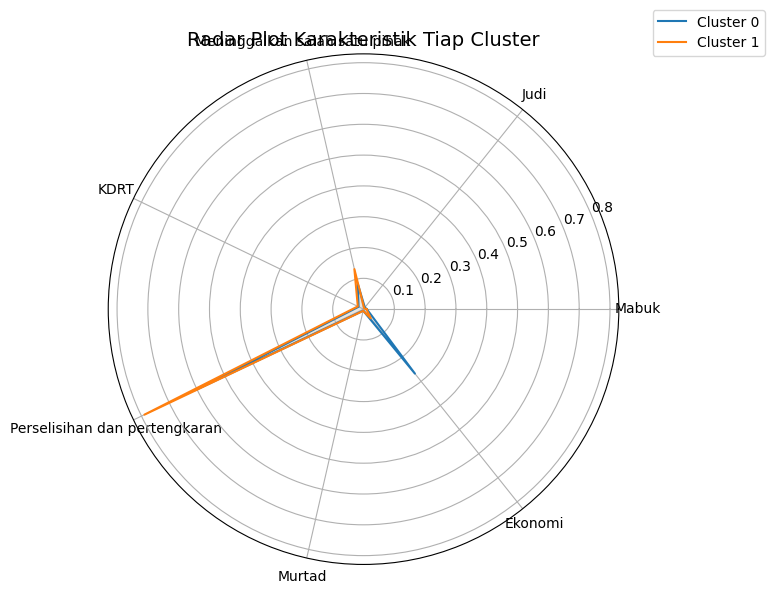

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Persiapkan data
data = rata_per_cluster.to_numpy()
labels = rata_per_cluster.columns.tolist()  # label indikator
n_vars = len(labels)

# Buat sudut untuk radar plot (1 lingkaran dibagi sesuai jumlah indikator)
angles = np.linspace(0, 2 * np.pi, n_vars, endpoint=False).tolist()
angles += angles[:1]  # loop kembali ke titik pertama

# Mulai membuat plot
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw=dict(polar=True))

# Buat radar plot per cluster
for i in range(len(data)):
    values = data[i].tolist()
    values += values[:1]  # ulang nilai pertama untuk menutup radar
    ax.plot(angles, values, label=f'Cluster {i}')
    ax.fill(angles, values, alpha=0.1)

# Tambahkan label indikator di sekeliling radar
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)

# Set opsi tampil
ax.set_title('Radar Plot Karakteristik Tiap Cluster', size=14)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()
